In [ ]:
!pip install gym gym_bandits

Number of arms: 10

Epsilon-Greedy Result
 ----------------------- 
Q-values: [ 0.2   0.13 -0.16 -0.11 -0.54  0.03  0.14 -0.11  0.04 -0.01]
Arm selection counts: [52 42 55 54 49 52 45 46 57 48]
Average reward: -0.19436566207562933


/tmp/ipykernel_510/4254373273.py:25: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  q_values[action] += (reward - q_values[action]) / counts[action]


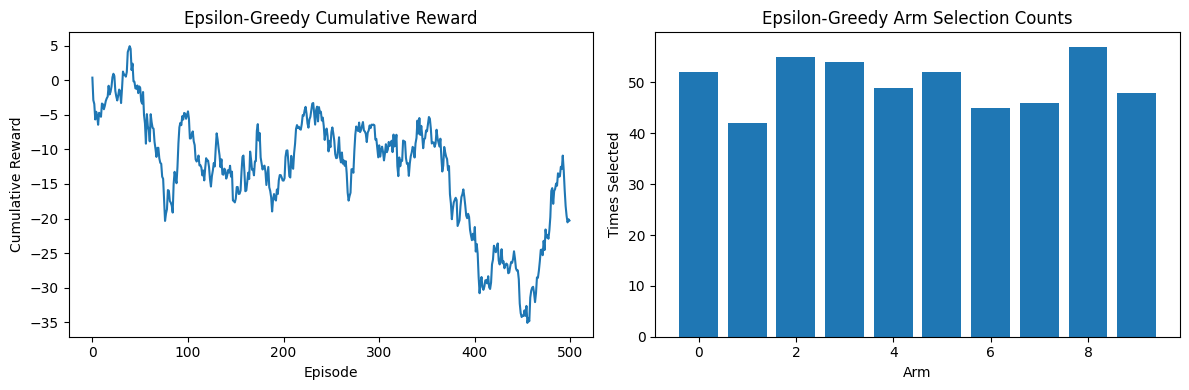


Softmax Result
 ----------------------- 
Q-values: [ 0.06 -0.22  0.08 -1.68  0.1   0.   -0.43  0.15 -1.74 -0.13]
Arm selection counts: [74 74 67  2 63 56 29 65  7 63]
Average reward: -1.3483524429981415


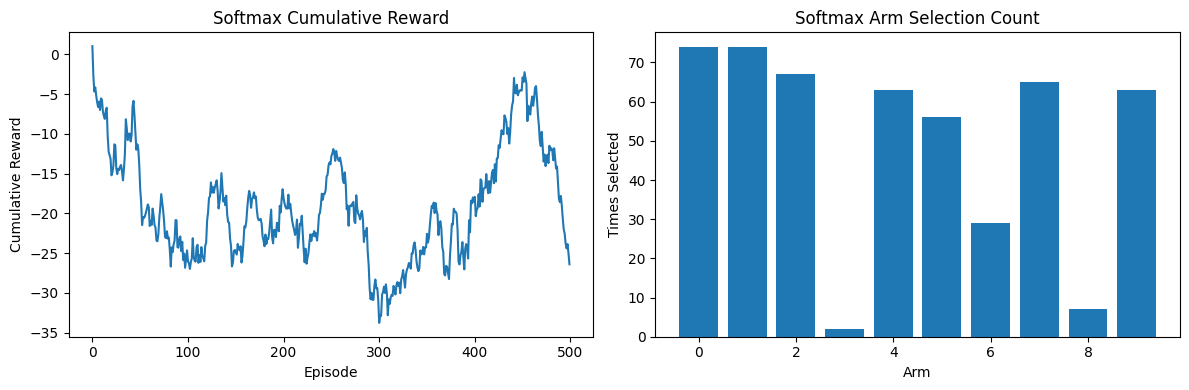

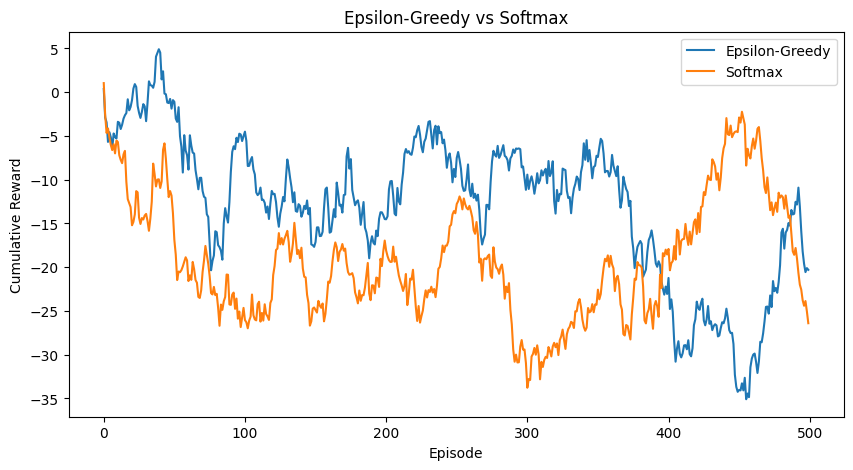

In [ ]:
import gym
import gym_bandits
import numpy as np
import matplotlib.pyplot as plt
np.bool8 = np.bool_

base_env = gym.make("MultiarmedBandits-v0")
env = base_env.unwrapped
n_arms = env.action_space.n
episodes = 500
print("Number of arms:",n_arms)

epsilon = 0.1
q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
rewards = []
for episode in range(episodes):
  env.reset()
  if np.random.rand() < epsilon:
    action = env.action_space.sample()
  else:
    action = env.action_space.sample()
  observations,reward,done,info = env.step(action)
  counts[action] += 1
  q_values[action] += (reward - q_values[action]) / counts[action]
  rewards.append(reward)
print("\nEpsilon-Greedy Result")
print(" ----------------------- ")
print("Q-values:",np.round(q_values ,2))
print("Arm selection counts:",counts.astype(int))
print("Average reward:",np.mean(reward))

plt.figure(figsize= (12,4))
plt.subplot(1,2,1)
plt.plot(np.cumsum(rewards))
plt.title("Epsilon-Greedy Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1,2,2)
plt.bar(range(n_arms),counts)
plt.title("Epsilon-Greedy Arm Selection Counts")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()

temperature = 0.5
q_values_softmax = np.zeros(n_arms)
counts_softmax = np.zeros(n_arms)
rewards_softmax = []
for episode in range (episodes):
  env.reset()
  probabilities = np.exp(q_values_softmax / temperature)
  probabilities = probabilities / np.sum(probabilities)
  action = np.random.choice(n_arms,p=probabilities)
  observations,reward,done,info = env.step(action)
  counts_softmax[action] += 1
  q_values_softmax[action] += (reward - q_values_softmax[action]) / counts_softmax[action]
  rewards_softmax.append(reward)
print("\nSoftmax Result")
print(" ----------------------- ")
print("Q-values:",np.round(q_values_softmax ,2))
print("Arm selection counts:",counts_softmax.astype(int))
print("Average reward:",np.mean(reward))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(rewards_softmax))
plt.title("Softmax Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts_softmax)
plt.title("Softmax Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(
    np.cumsum(rewards),
    label="Epsilon-Greedy"
)
plt.plot(
    np.cumsum(rewards_softmax),
    label="Softmax"
)
plt.title("Epsilon-Greedy vs Softmax")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.legend()
plt.show()
env.close()